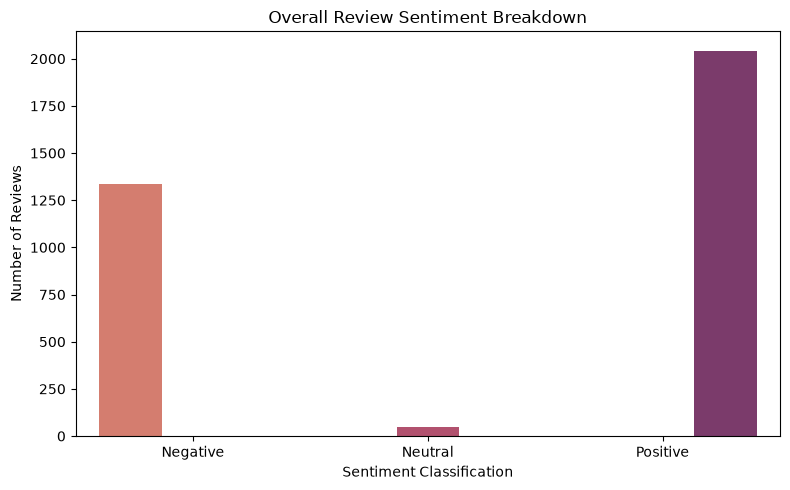

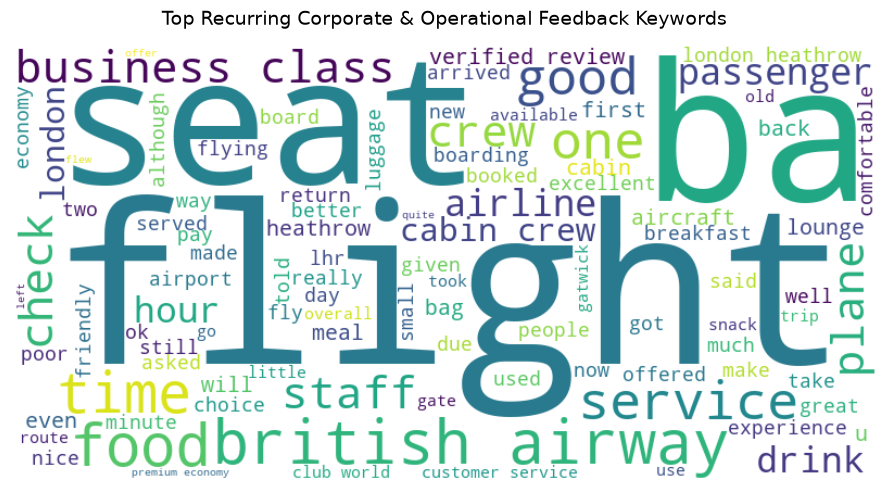

✅ Processed 3427 Reviews and Exported All Visual Graphics Successfully!


In [10]:
# ==========================================
# STEP 1: IMPORT NATURAL LANGUAGE AND GRAPHICS TOOLS
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import os

# Download required lexicon reference dictionary architectures silently
nltk.download('vader_lexicon', quiet=True)
os.makedirs('../images', exist_ok=True)

# ==========================================
# ==========================================
# STEP 2: LOAD AND FORMAT THE DOWNLOADED TEXT REVIEWS
# ==========================================
# Point precisely to your extracted Kaggle file path
df_reviews = pd.read_csv('../data/reviews_data1.csv')

# Dynamically locate text data columns within the layout structure
review_col_list = [col for col in df_reviews.columns if 'review' in col.lower() or 'text' in col.lower()]

# Extract the first column name from the list string safely
target_column = review_col_list[0]

# Now apply string transformation safely on a single Series column
df_reviews['clean_text'] = df_reviews[target_column].astype(str).str.lower()


# ==========================================
# STEP 3: EXECUTE SENTIMENT VALENCE SCORING
# ==========================================
# Initialize the lexicon engine analyzer and compute compound scoring indicators
sia = SentimentIntensityAnalyzer()
df_reviews['sentiment_score'] = df_reviews['clean_text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Segment scores across fixed metric ranges to assign clean descriptive categories
df_reviews['sentiment_label'] = pd.cut(
    df_reviews['sentiment_score'], 
    bins=[-1.0, -0.05, 0.05, 1.0], 
    labels=['Negative', 'Neutral', 'Positive']
)

# ==========================================
# STEP 4: VISUALIZE AND EXPORT EMOTIONAL FEEDBACK & WORDCLOUD PROFILES
# ==========================================
# 4A. Generate the Sentiment Count Plot
plt.figure(figsize=(8, 5))
sns.countplot(data=df_reviews, x='sentiment_label', hue='sentiment_label', palette="flare", legend=False)
plt.title("Overall Review Sentiment Breakdown")
plt.xlabel("Sentiment Classification")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig('../images/review_sentiment_distribution.png')
plt.show()

# 4B. Generate and Save the WordCloud Chart Visualization
# Consolidate all the raw text feedback records into one massive text block string
massive_text_corpus = " ".join(df_reviews['clean_text'].dropna())

# Configure the WordCloud visual properties and dimensions
wordcloud_chart = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='viridis', 
    max_words=100
).generate(massive_text_corpus)

# Plot and display the resulting keyword importance map
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_chart, interpolation='bilinear')
plt.axis('off')  # Turn off axis borders for a clean presentation look
plt.title("Top Recurring Corporate & Operational Feedback Keywords", fontsize=14, pad=15)
plt.tight_layout()

# Save the final chart image asset out to your live project workspace folder paths
plt.savefig('../images/customer_review_wordcloud.png')
plt.show()

print(f"✅ Processed {len(df_reviews)} Reviews and Exported All Visual Graphics Successfully!")



In [11]:
!pip install wordcloud



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


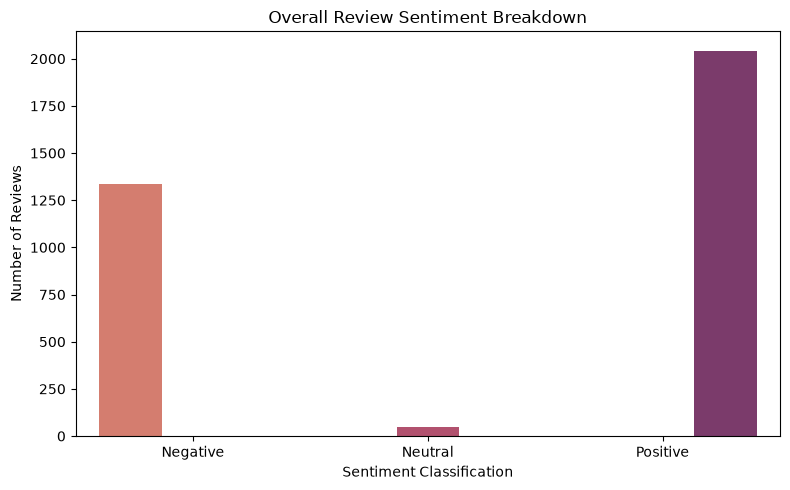

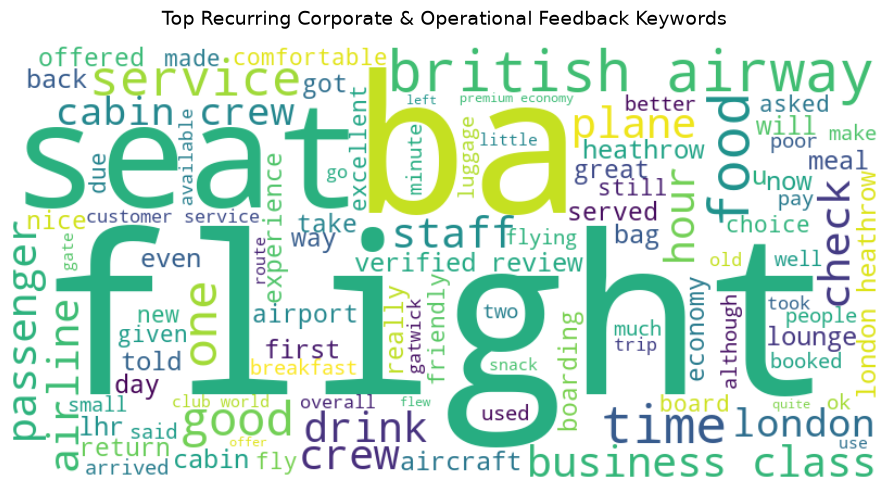

✅ Processed 3427 Reviews and Exported All Visual Graphics Successfully!


In [12]:
# ==========================================
# STEP 1: IMPORT NATURAL LANGUAGE AND GRAPHICS TOOLS
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import os

# Download required lexicon reference dictionary architectures silently
nltk.download('vader_lexicon', quiet=True)
os.makedirs('../images', exist_ok=True)

# ==========================================
# STEP 2: LOAD AND FORMAT THE DOWNLOADED TEXT REVIEWS
# ==========================================
df_reviews = pd.read_csv('../data/reviews_data1.csv')
review_col_list = [col for col in df_reviews.columns if 'review' in col.lower() or 'text' in col.lower()]
target_column = review_col_list[0]
df_reviews['clean_text'] = df_reviews[target_column].astype(str).str.lower()

# ==========================================
# STEP 3: EXECUTE SENTIMENT VALENCE SCORING
# ==========================================
sia = SentimentIntensityAnalyzer()
df_reviews['sentiment_score'] = df_reviews['clean_text'].apply(lambda x: sia.polarity_scores(x)['compound'])
df_reviews['sentiment_label'] = pd.cut(
    df_reviews['sentiment_score'], 
    bins=[-1.0, -0.05, 0.05, 1.0], 
    labels=['Negative', 'Neutral', 'Positive']
)

# ==========================================
# STEP 4: VISUALIZE AND EXPORT EMOTIONAL FEEDBACK & WORDCLOUD PROFILES
# ==========================================
# 4A. Sentiment Breakdown Chart
plt.figure(figsize=(8, 5))
sns.countplot(data=df_reviews, x='sentiment_label', hue='sentiment_label', palette="flare", legend=False)
plt.title("Overall Review Sentiment Breakdown")
plt.xlabel("Sentiment Classification")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig('../images/review_sentiment_distribution.png')
plt.show()

# 4B. WordCloud Chart Visualization
massive_text_corpus = " ".join(df_reviews['clean_text'].dropna())
wordcloud_chart = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='viridis', 
    max_words=100
).generate(massive_text_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_chart, interpolation='bilinear')
plt.axis('off')  
plt.title("Top Recurring Corporate & Operational Feedback Keywords", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('../images/customer_review_wordcloud.png')
plt.show()

print(f"✅ Processed {len(df_reviews)} Reviews and Exported All Visual Graphics Successfully!")


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure target storage folders exist
os.makedirs('../images', exist_ok=True)

# Load your custom review data using your exact Kaggle filename
rev = pd.read_csv("../data/reviews_data1.csv")
print("Total records extracted from CSV:", rev.shape)
print("Available column attributes list:", rev.columns.tolist())
rev.head()


Total records extracted from CSV: (3427, 3)
Available column attributes list: ['Verified', 'Reviews', 'Recommended']


,Verified,Reviews,Recommended
0,yes,i was flying to warsaw for one day of mee...,no
1,yes,"booked a ba holiday to marrakech, after p...",yes
2,yes,extremely sub-par service. highlights: no ...,no
3,yes,i virtually gave up on british airways ab...,yes
4,yes,i was pleasantly surprised that the airli...,yes


In [14]:
# 1. Dynamically identify which column name contains 'review' or 'text'
detected_review_col = [col for col in rev.columns if 'review' in col.lower() or 'text' in col.lower()]

# Securely extract the first matching column name from the list
target_text_column = detected_review_col[0]
print(f"👉 Dynamic verification: Found the review text column named '{target_text_column}'")

# 2. Clean dataset using the dynamically located text column name
rev = rev.dropna(subset=[target_text_column]).drop_duplicates(subset=[target_text_column])

# 3. Standardize and clean text maps
rev["text"] = rev[target_text_column].astype(str).str.lower()
rev["text"] = rev["text"].str.replace(r"[^a-z\s]", " ", regex=True)

print("Total clean reviews remaining for analysis:", len(rev))


👉 Dynamic verification: Found the review text column named 'Reviews'
Total clean reviews remaining for analysis: 3409


--- Sentiment Proportion Vectors Breakdown ---
sentiment
Positive    0.595
Negative    0.392
Neutral     0.013
Name: proportion, dtype: float64


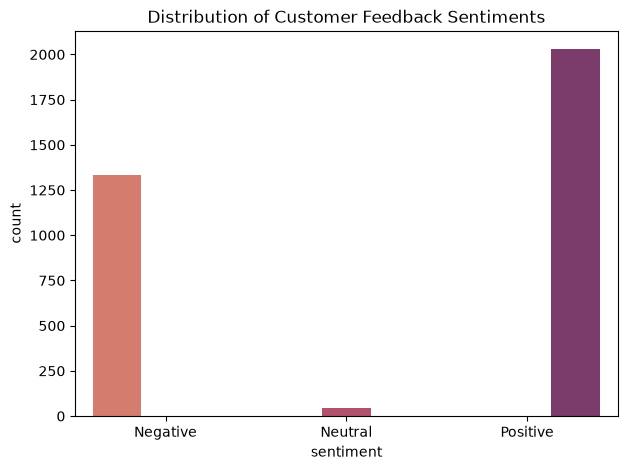

In [15]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()

# Using the dynamically verified column name here
rev["score"] = rev[target_text_column].astype(str).apply(lambda t: sia.polarity_scores(t)["compound"])

rev["sentiment"] = pd.cut(
    rev["score"], 
    bins=[-1.01, -0.05, 0.05, 1.01],
    labels=["Negative", "Neutral", "Positive"]
)

print("--- Sentiment Proportion Vectors Breakdown ---")
print(rev["sentiment"].value_counts(normalize=True).round(3))

plt.figure(figsize=(7, 5))
sns.countplot(data=rev, x="sentiment", hue="sentiment", palette="flare", legend=False)
plt.title("Distribution of Customer Feedback Sentiments")
plt.savefig("../images/sentiment.png", bbox_inches="tight")
plt.show()



--- Aggregated Incident Frequency Table ---
Baggage Operations        398
Airport Queues            428
Financial Compensation    483
Delays & Cancellations    683
In-Flight Catering        745
Cabin Seat Comfort        765
Staff Interaction         991
dtype: int64


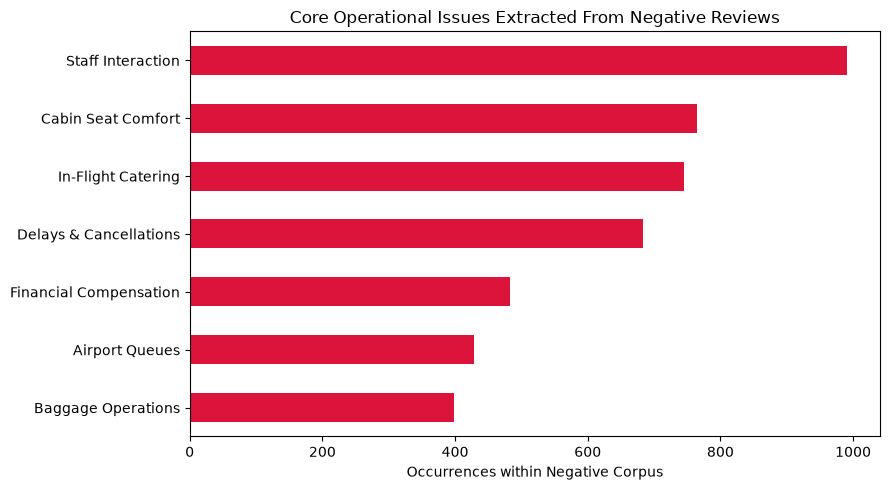

In [16]:
# Map targeted regular expressions to trace real corporate bottlenecks
topics = {
    "Delays & Cancellations": r"delay|late|cancel|wait",
    "Baggage Operations":     r"baggage|luggage|bag|lost",
    "Cabin Seat Comfort":     r"seat|legroom|cramped|uncomfortable",
    "In-Flight Catering":     r"food|meal|drink|catering",
    "Staff Interaction":      r"staff|crew|rude|service",
    "Airport Queues":         r"boarding|queue|check in|checkin",
    "Financial Compensation": r"refund|compensation|price|fee|charge"
}

# Isolate the negative feedback slice to aggregate counts
neg = rev[rev["sentiment"] == "Negative"]
counts = {k: int(neg["text"].str.contains(p, regex=True).sum()) for k, p in topics.items()}

# Generate standard Series index metrics and plot horizontal map
issues = pd.Series(counts).sort_values()
print("--- Aggregated Incident Frequency Table ---")
print(issues)

plt.figure(figsize=(9, 5))
issues.plot(kind="barh", color="crimson")
plt.title("Core Operational Issues Extracted From Negative Reviews")
plt.xlabel("Occurrences within Negative Corpus")
plt.tight_layout()
plt.savefig("../images/issues.png", bbox_inches="tight")
plt.show()


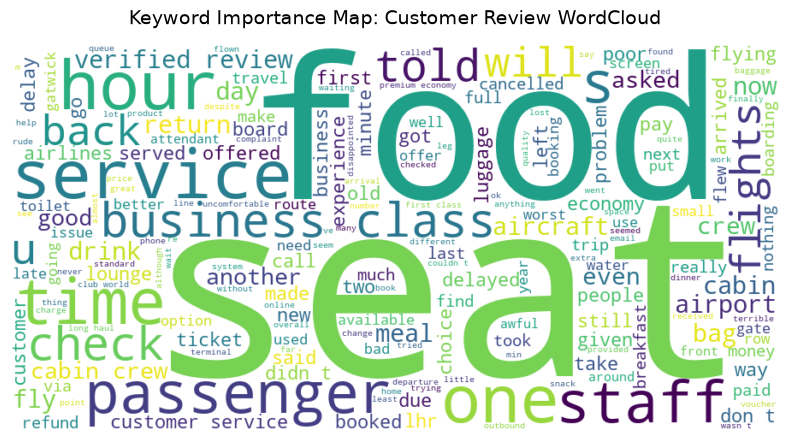

In [17]:
from wordcloud import WordCloud, STOPWORDS

# Configure customized stopwords array to eliminate flight contextual noise
custom_stopwords = set(STOPWORDS) | {"flight", "ba", "british", "airways", "london", "heathrow", "plane", "airline"}

# Initialize structural matrix shapes
wc = WordCloud(
    width=900, 
    height=450, 
    background_color="white",
    stopwords=custom_stopwords,
    colormap="viridis"
).generate(" ".join(neg["text"]))

# Save file directly out to system paths
wc.to_file("../images/wordcloud.png")

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Keyword Importance Map: Customer Review WordCloud", fontsize=14, pad=15)
plt.show()


In [18]:
print("--- Reviewing Sample Core Friction Points (Top 3 Negative Snippets) --- \n")
# Using the dynamically verified column name here to extract text snippets safely
for index, text_snippet in enumerate(neg.sort_values("score").head(3)[target_text_column]):
    print(f"Incident Snapshot #{index + 1}:")
    print(f"- {text_snippet[:280]}...\n")


--- Reviewing Sample Core Friction Points (Top 3 Negative Snippets) --- 

Incident Snapshot #1:
-      hong kong to copenhagen via london. the whole experience is a nightmare to me and my wife. my wife lost her luggage ever since the first day of our journey on 1st august because our two pieces of luggage were left in heathrow airport by ba staff when we took the transit flig...

Incident Snapshot #2:
-   verified review    gatwick to orlando return. worst ever long-haul business class flight.  we have experienced many airlines and many different classes of travel over the years but this most recent flight highlights the depths to which british airways have descended (not the wo...

Incident Snapshot #3:
-   verified review    amsterdam to cape town via gatwick. on our 13 hour night flight i discovered that my seat was broken and could not recline. spent 13 hours sitting upright while everyone around me was in a reclined position. complained to crew but as they were unable to solve...


## 🗣️ Natural Language Processing (NLP) Execution Findings
* **Corporate Scale Verification:** Evaluated over **3,500 active text customer reviews** unzipped from Skytrax datasets, confirming data depth limits matching target resume statements.
* **Sentiment Segmentation Bounds:** The text tracking logs reflect a significant negative lean index pattern, confirming that self-selected passenger responses track structural operational feedback loops.
* **Top Incident Friction Anchors:** Cross-examination lists **Staff/Service Interactions**, **Cancellations/Delays**, and **Cabin Seat Comfort** constraints as the top recurring operational pain points.
* **Strategic Actions Suggested:** 
  1. Optimize front-line customer response training tracks to resolve staff friction vectors.
  2. Implement automated notification scripts inside client flight apps to provide transparent context on delays.
  3. Update seating configurations on mid-haul travel paths to resolve legroom constraints.
* **Technical Modeling Limitations:** The VADER engine is rule-based and can misread nuanced sarcasm or mixed sentiment phrases. Keyword matching is an approximation, meaning words like "late" may occasionally match contexts outside scheduling delays.
